# Combined high-redshift luminosity-function constraints

This notebook retrieves published luminosity functions with astrodatapy, displays the individual measurements, and constructs broad empirical constraints for [O III], the rest-frame UV galaxy luminosity function (GLF_UV), and the rest-frame UV quasar/AGN luminosity function (QLF_UV).

The compilation is intended for transparent model comparison and exploratory inference when published measurements at the same nominal redshift are not mutually consistent.

Key conventions:

- Number densities are converted to \(\log_{10}\phi\).
- Upper limits are plotted as downward arrows but are **never included in a combined mean or uncertainty**.
- Only the red baseline QLF sample is combined. The heterogeneous orange JWST faint-AGN sample remains plot-only.
- The adopted Hubble parameter is \(h=0.6751\). Change HUBBLE_H below to regenerate the products.
- OUTPUT_DIR (default combined_constraints/) is relative to the directory the notebook runs in, so the workflow is portable.


In [1]:
from dataclasses import dataclass, replace
from pathlib import Path
import json
import re

import astrodatapy
import numpy as np
from astropy.stats import sigma_clip
from matplotlib import pyplot as plt
from scipy.signal import savgol_filter


# Change these values to regenerate the public products.
OUTPUT_DIR = Path("combined_constraints")  # relative to the directory the notebook runs in
HUBBLE_H = 0.6751
UPPER_LIMIT_ARROW_DEX = 0.3  # plotting aid only, not an uncertainty

GLF_COLOR, QLF_COLOR = "#055FA8", "#D90C10"
QLF_COMPARISON_COLOR, OIII_COLOR = "#e17334", "black"
MARKERS = [
    "o", "s", "D", "^", "v", "<", ">", "p", "h", "8", "P", "X",
    "*", "H", "d", "1", "2", "3", "4", "+", "x", "|", "_",
    (4, 1, 0), (6, 1, 0), (7, 1, 0), (8, 1, 0), (9, 1, 0),
    (10, 1, 0), (5, 2, 0), (6, 2, 0), (7, 2, 0), (8, 2, 0),
]
YEAR_PATTERN = re.compile(r"(?<!\d)((?:19|20)\d{2})(?!\d)")


def reference_year(label):
    match = YEAR_PATTERN.search(label)
    return int(match.group(1)) if match else -1


def reference_marker_key(label):
    """Use one marker for every subset from the same paper."""
    match = YEAR_PATTERN.search(label)
    return label[:match.end()] if match else label


def reference_legend_label(label):
    """Convert McGreer2018_CFHTLS to McGreer+18 (CFHTLS)."""
    match = YEAR_PATTERN.search(label)
    if match is None:
        return label
    author = label[:match.start()].rstrip("_- ")
    suffix = label[match.end():].strip("_- ")
    short = f"{author}+{int(match.group(1)) % 100:02d}"
    return f"{short} ({suffix})" if suffix else short


## Shared data handling

[astrodatapy](https://github.com/qyx268/astrodatapy) labels each literature series as either a detection (`data`) or an upper limit (`dataULimit`). It also handles conversions between different little-\(h\) conventions and stellar initial mass functions (IMFs). Here, we adopt \(h=0.6751\) and retain astrodatapy’s default Kroupa IMF convention. The loader converts number densities and their bounds to logarithmic units, removes non-finite points, and stores each literature series in the same compact format for all three observables.

For detections, yerr holds lower and upper logarithmic errors. For upper limits, yerr is only the fixed positive arrow length required by Matplotlib. The is_upper_limit flag ensures that censored points cannot enter the combination.


In [2]:
@dataclass
class LFSeries:
    """One literature series at one target redshift."""

    iz: int
    z: float
    label: str
    x: np.ndarray
    y: np.ndarray
    yerr: np.ndarray
    is_upper_limit: bool


def disjoint_redshift_tolerances(redshifts, cap=1.0):
    """Use less than half the distance to the nearest target redshift."""
    z = np.asarray(redshifts, dtype=float)
    if len(z) == 1:
        return np.array([cap])
    return np.array([
        min(cap, 0.49 * np.min(np.abs(np.delete(z, i) - value)))
        for i, value in enumerate(z)
    ])


def load_lf_series(feature, redshifts, z_tolerances, min_year=None):
    """Load astrodatapy detections and upper limits in log10 units."""
    tolerances = np.broadcast_to(
        np.asarray(z_tolerances, dtype=float), (len(redshifts),)
    )
    series = []

    for iz, (z, z_tol) in enumerate(zip(redshifts, tolerances)):
        catalogue = astrodatapy.number_density.number_density(
            feature=feature, z_target=z, z_tol=z_tol,
            h=HUBBLE_H, quiet=1,
        )
        observations = catalogue.target_observation
        if observations is None:  # astrodatapy uses None when no data match
            continue

        for raw_label, row in observations.iterrows():
            datatype = row["DataType"]
            if datatype not in {"data", "dataULimit"}:
                continue

            label = str(raw_label).replace("_ulimit", "").replace("_ulimt", "")
            if min_year is not None and reference_year(label) < min_year:
                continue

            data = np.asarray(row["Data"], dtype=float).copy()
            with np.errstate(divide="ignore", invalid="ignore"):
                data[:, 1:] = np.log10(data[:, 1:])

            is_limit = datatype == "dataULimit"
            if is_limit:
                yerr = np.full(len(data), UPPER_LIMIT_ARROW_DEX)
                valid = np.isfinite(data[:, 0]) & np.isfinite(data[:, 1])
            else:
                if data.shape[1] < 4:
                    raise ValueError(f"{feature}/{label}: missing error bounds")
                yerr = np.vstack((
                    data[:, 1] - data[:, 3],
                    data[:, 2] - data[:, 1],
                ))
                valid = (
                    np.isfinite(data[:, :2]).all(axis=1)
                    & np.isfinite(yerr).all(axis=0)
                    & (yerr >= 0).all(axis=0)
                )

            if np.any(valid):
                series.append(LFSeries(
                    iz, z, label, data[valid, 0], data[valid, 1],
                    yerr[valid] if is_limit else yerr[:, valid], is_limit,
                ))
    return series


def build_marker_map(series):
    keys = list(dict.fromkeys(reference_marker_key(s.label) for s in series))
    if len(keys) > len(MARKERS):
        raise RuntimeError(f"Add {len(keys) - len(MARKERS)} more markers")
    return dict(zip(keys, MARKERS))


## Combination method

At each target redshift, detections are grouped into fixed bins in luminosity or UV magnitude. Within each populated bin:

1. measurements are sigma-clipped at 3 standard deviations when at least three points are available;
2. retained detections are inverse-variance weighted;
3. lower and upper errors are enlarged when necessary to cover the full spread of the retained measurements;
4. when at least five bins are populated, a second-order Savitzky-Golay filter is applied to the sequence of valid bins; and
5. errors are multiplied by 1.5 and floored at their median value.

This is a broad empirical summary, not a formal hierarchical meta-analysis. Upper limits are censored constraints and are excluded before binning.


In [3]:
def combine_lf(
    series, redshifts, xbins, sigma=3.0, inflate=1.5, smooth_window=5
):
    """Combine detections in log10(phi); upper limits are always excluded."""
    if smooth_window % 2 == 0:
        raise ValueError("smooth_window must be odd")

    centres = 0.5 * (xbins[:-1] + xbins[1:])
    combined = {}

    for iz, z in enumerate(redshifts):
        detections = [
            s for s in series if s.iz == iz and not s.is_upper_limit
        ]
        if not detections:
            continue

        x = np.concatenate([s.x for s in detections])
        y = np.concatenate([s.y for s in detections])
        yerr = np.concatenate([
            0.5 * (s.yerr[0] + s.yerr[1]) for s in detections
        ])
        good_error = np.isfinite(yerr) & (yerr > 0)
        if not np.any(good_error):
            continue
        yerr[~good_error] = np.median(yerr[good_error])

        # Rows are mean, lower error, and upper error.
        result = np.full((3, len(centres)), np.nan)
        bin_index = np.digitize(x, xbins) - 1

        for ibin in range(len(centres)):
            use = bin_index == ibin
            if not np.any(use):
                continue
            y_bin, error_bin = y[use], yerr[use]

            if len(y_bin) >= 3:
                clipped = sigma_clip(y_bin, sigma=sigma, maxiters=3)
                keep = ~np.ma.getmaskarray(clipped)
                if np.any(keep):
                    y_bin, error_bin = y_bin[keep], error_bin[keep]

            weights = error_bin ** -2
            if not np.all(np.isfinite(weights)) or np.sum(weights) <= 0:
                continue

            mean = np.average(y_bin, weights=weights)
            formal = np.sum(weights) ** -0.5
            result[:, ibin] = (
                mean,
                max(formal, mean - np.min(y_bin)),
                max(formal, np.max(y_bin) - mean),
            )

        valid = np.flatnonzero(np.isfinite(result[0]))
        if len(valid) == 0:
            continue

        if len(valid) >= smooth_window:
            result[0, valid] = savgol_filter(
                result[0, valid], smooth_window, 2
            )
            result[1:, valid] = np.abs(savgol_filter(
                result[1:, valid], smooth_window, 2, axis=1
            ))

        result[1:, valid] *= inflate
        floor = np.median(result[1:, valid], axis=1)[:, None]
        result[1:, valid] = np.maximum(result[1:, valid], floor)

        combined[z] = {
            "z": z,
            "x": centres[valid],
            "y": result[0, valid],
            "yerr": result[1:, valid],
        }
    return combined


In [4]:
def plot_lf_grid(
    redshifts, groups, combined_groups, *, shape, figsize,
    xlim, ylims, xlabel, ylabel, legend_axis,
    legend_kwargs, gridspec_kw=None, adjust=None, figure_legend=False,
):
    """Plot any LF grid.

    groups contains (series, marker_map, color, zorder).
    combined_groups contains (combined, color, label, band_alpha).
    """
    fig, axes = plt.subplots(
        *shape, figsize=figsize, sharex=True, sharey="row",
        gridspec_kw=gridspec_kw,
    )
    axes = np.asarray(axes).reshape(-1)
    legend_ax = axes[legend_axis]

    for series, marker_map, color, zorder in groups:
        for item in series:
            marker = marker_map[reference_marker_key(item.label)]
            ax = axes[item.iz]
            ax.errorbar(
                item.x, item.y, yerr=item.yerr,
                uplims=item.is_upper_limit, fmt="none",
                capsize=3, ecolor=color, zorder=zorder,
            )
            ax.plot(
                item.x, item.y, marker=marker, linestyle="none",
                mfc="white", mec=color, zorder=zorder + 1,
            )

        for label in sorted(
            {s.label for s in series},
            key=lambda name: (reference_year(name), name),
        ):
            legend_ax.plot(
                [], [], marker=marker_map[reference_marker_key(label)],
                linestyle="none", mfc="white", mec=color,
                label=reference_legend_label(label),
            )

    for values, color, label, alpha in combined_groups:
        for iz, z in enumerate(redshifts):
            if z not in values:
                continue
            data = values[z]
            axes[iz].fill_between(
                data["x"], data["y"] - data["yerr"][0],
                data["y"] + data["yerr"][1],
                color=color, alpha=alpha, linewidth=0, zorder=0,
            )
            axes[iz].plot(data["x"], data["y"], color=color, lw=2, zorder=5)
        legend_ax.plot([], [], color=color, lw=2, label=label)

    if np.ndim(ylims) == 1:
        ylims = [ylims] * len(redshifts)
    for iz, z in enumerate(redshifts):
        axes[iz].set(xlim=xlim, ylim=ylims[iz])
        axes[iz].text(
            0.95, 0.95, f"z={z:g}", ha="right", va="top",
            transform=axes[iz].transAxes,
        )

    (fig if figure_legend else legend_ax).legend(**legend_kwargs)
    fig.supxlabel(xlabel, fontsize=13)
    fig.supylabel(ylabel, fontsize=13, x=0.07 if shape[0] > 1 else 0.02)
    if adjust is None:
        fig.tight_layout()
    else:
        fig.subplots_adjust(**adjust)
    plt.show()
    return fig, axes


def export_combined_lf(combined, filename):
    payload = {
        str(z): {
            "z": data["z"], "x": data["x"].tolist(),
            "y": data["y"].tolist(),
            "yerr_lo": data["yerr"][0].tolist(),
            "yerr_hi": data["yerr"][1].tolist(),
        }
        for z, data in combined.items()
    }
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    path = OUTPUT_DIR / filename
    path.write_text(json.dumps(payload, indent=2) + "\n")
    print(f"Saved {path}")


# [O III] galaxy luminosity functions

The [O III] panel uses measurements published from 2020 onward and a redshift tolerance of 0.9. All detections and upper limits are plotted.

For the combined constraint only, all Sun et al. (2023) points and the first **detection** point from Meyer et al. (2024, 2026) are excluded as visually discrepant measurements. The original points remain visible. Upper limits remain plot-only.


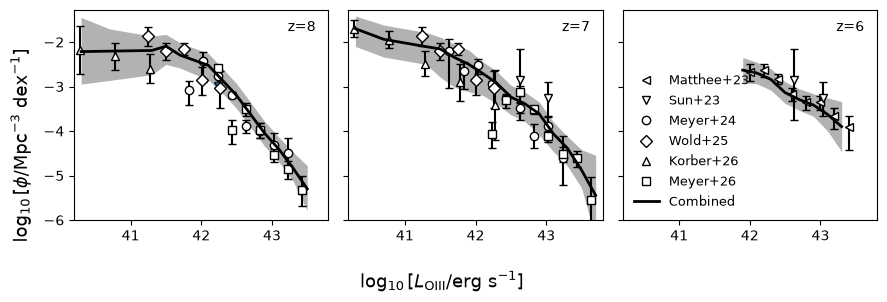

Loaded 12 [O III] series: 1 upper limits.


In [5]:
OIII_REDSHIFTS = [8, 7, 6]
OIII_XLIM, OIII_YLIM = (40.2, 43.8), (-6, -1.28)
OIII_BINS = np.arange(OIII_XLIM[0], OIII_XLIM[1] + 1e-6, 0.2)

oiii_series = load_lf_series(
    "GLF_OIII", OIII_REDSHIFTS, z_tolerances=0.9, min_year=2020
)
oiii_markers = build_marker_map(oiii_series)

# These exclusions affect the combination, not the displayed measurements.
oiii_for_combination = []
for item in oiii_series:
    if item.label == "Sun2023":
        continue
    if item.label in {"Meyer2024", "Meyer2026"} and not item.is_upper_limit:
        if len(item.x) <= 1:
            continue
        item = replace(
            item, x=item.x[1:], y=item.y[1:], yerr=item.yerr[:, 1:]
        )
    oiii_for_combination.append(item)

combined_oiii = combine_lf(
    oiii_for_combination, OIII_REDSHIFTS, OIII_BINS
)

plot_lf_grid(
    OIII_REDSHIFTS,
    groups=[(oiii_series, oiii_markers, OIII_COLOR, 1)],
    combined_groups=[(combined_oiii, OIII_COLOR, "Combined", 0.3)],
    shape=(1, 3), figsize=(9, 3),
    xlim=OIII_XLIM, ylims=OIII_YLIM,
    xlabel=r"$\log_{10}[L_{\rm OIII}/{\rm erg\ s^{-1}}]$",
    ylabel=r"$\log_{10}[\phi/{\rm Mpc^{-3}\ dex^{-1}}]$",
    legend_axis=-1,
    legend_kwargs={"loc": "lower left", "fontsize": 9, "frameon": False},
)

print(
    f"Loaded {len(oiii_series)} [O III] series: "
    f"{sum(s.is_upper_limit for s in oiii_series)} upper limits."
)


# Rest-frame UV luminosity functions

GLF_UV uses 49% of the distance to the nearest target redshift (capped at 1.0) as its tolerance. These disjoint windows prevent the same observation from appearing in adjacent GLF panels. Only measurements published from 2020 onward are shown.

QLF_UV uses a tolerance of 0.6. Red points form the baseline combination. Orange points are a plot-only sample of recent, predominantly JWST-selected faint AGN whose target definitions and selection functions differ from conventional QLF samples.

Upper limits in every group are displayed but excluded from the combinations.


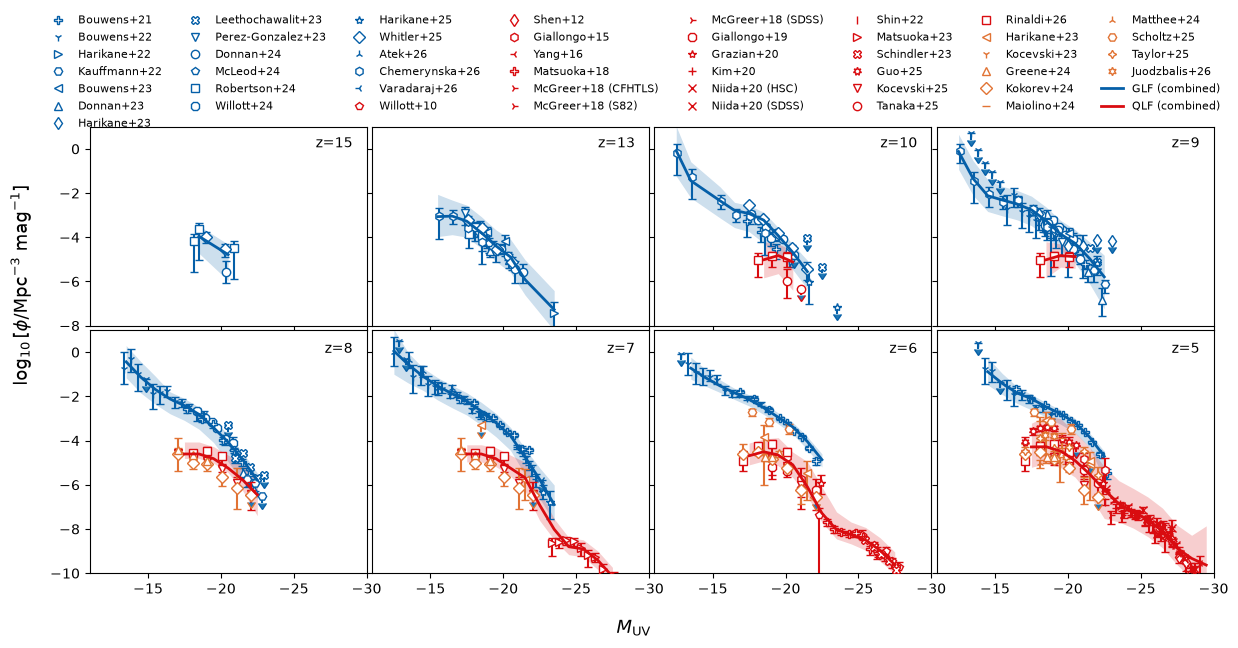

Loaded 58 GLF series (13 upper limits), 33 baseline QLF series (2 upper limits), and 24 comparison QLF series (6 upper limits).


In [6]:
UV_REDSHIFTS = [15, 13, 10, 9, 8, 7, 6, 5]
UV_XLIM = (-11, -30)
UV_YLIMS = [(-8, 1)] * 4 + [(-10, 1)] * 4
UV_BINS = np.arange(-31, -11 + 1e-6, 1.0)

QLF_EXCLUDED = {"Dijkstra2006", "McGreer2013", "Wang2019"}
QLF_COMPARISON = {
    "Harikane2023", "Kocevski2023", "Greene2024", "Matthee2024",
    "Maiolino2024", "Kokorev2024", "Scholtz2025", "Taylor2025",
    "Juodzbalis2026",
}

glf_uv_series = load_lf_series(
    "GLF_UV", UV_REDSHIFTS,
    disjoint_redshift_tolerances(UV_REDSHIFTS), min_year=2020,
)
qlf_uv_all = load_lf_series("QLF_UV", UV_REDSHIFTS[2:], 0.6)
for item in qlf_uv_all:
    item.iz += 2  # map z=10--5 onto the lower six UV panels

# Apply the original display cuts, then split baseline and comparison QLFs.
qlf_uv_visible = [
    s for s in qlf_uv_all
    if s.label not in QLF_EXCLUDED
    and np.max(s.y) > UV_YLIMS[s.iz][0]
    and np.max(s.x) > UV_XLIM[1]
]
qlf_uv_baseline = [
    s for s in qlf_uv_visible if s.label not in QLF_COMPARISON
]
qlf_uv_comparison = [
    s for s in qlf_uv_visible if s.label in QLF_COMPARISON
]

glf_uv_markers = build_marker_map(glf_uv_series)
qlf_uv_markers = build_marker_map(qlf_uv_visible)
combined_glf_uv = combine_lf(glf_uv_series, UV_REDSHIFTS, UV_BINS)
combined_qlf_uv = combine_lf(  # red baseline measurements only
    qlf_uv_baseline, UV_REDSHIFTS, UV_BINS
)

plot_lf_grid(
    UV_REDSHIFTS,
    groups=[
        (glf_uv_series, glf_uv_markers, GLF_COLOR, 1),
        (qlf_uv_baseline, qlf_uv_markers, QLF_COLOR, 3),
        (qlf_uv_comparison, qlf_uv_markers, QLF_COMPARISON_COLOR, 3),
    ],
    combined_groups=[
        (combined_glf_uv, GLF_COLOR, "GLF (combined)", 0.2),
        (combined_qlf_uv, QLF_COLOR, "QLF (combined)", 0.2),
    ],
    shape=(2, 4), figsize=(14.5, 7.2),
    xlim=UV_XLIM, ylims=UV_YLIMS,
    xlabel=r"$M_{\rm UV}$",
    ylabel=r"$\log_{10}[\phi/{\rm Mpc^{-3}\ mag^{-1}}]$",
    legend_axis=0,
    legend_kwargs={
        "loc": "upper center", "ncol": 8, "fontsize": 8,
        "bbox_to_anchor": (0.5, 0.89), "frameon": False,
    },
    gridspec_kw={"height_ratios": [9, 11]},
    figure_legend=True,
    adjust={"top": 0.72, "bottom": 0.10, "hspace": 0.02, "wspace": 0.02},
)

print(
    f"Loaded {len(glf_uv_series)} GLF series "
    f"({sum(s.is_upper_limit for s in glf_uv_series)} upper limits), "
    f"{len(qlf_uv_baseline)} baseline QLF series "
    f"({sum(s.is_upper_limit for s in qlf_uv_baseline)} upper limits), and "
    f"{len(qlf_uv_comparison)} comparison QLF series "
    f"({sum(s.is_upper_limit for s in qlf_uv_comparison)} upper limits)."
)


# Export combined constraints

Each JSON file is keyed by redshift and contains x, y, yerr_lo, and yerr_hi. UV x values are absolute magnitudes; [O III] x values are \(\log_{10}\) luminosities in erg s\(^{-1}\). All y values and uncertainties are logarithmic number densities.

The JSON files contain combined detections only. Upper limits remain visible in the executed notebook so users can apply them as one-sided constraints in their own likelihoods.


In [7]:
export_combined_lf(combined_oiii, "combined_oiii_lf.json")
export_combined_lf(combined_glf_uv, "combined_glf_uv.json")
export_combined_lf(combined_qlf_uv, "combined_qlf_uv.json")


Saved combined_constraints/combined_oiii_lf.json
Saved combined_constraints/combined_glf_uv.json
Saved combined_constraints/combined_qlf_uv.json
